# 06 · What the models look at

Two ways to look inside a detector, one per family:

1. **Grad-CAM on a CNN detector** (YOLO11s): which backbone / neck level explains a detection, for small and large objects, found and missed ones.
2. **RT-DETR internals**: where the decoder's deformable cross-attention samples at each layer, and what the query embeddings look like (t-SNE).

Everything is computed on fold-0 validation frames with the checkpoints trained for the main experiments (`yolo_base`, `rtdetr_s5_1536`). Training curves, configs and validation predictions with boxes are logged to Weights & Biases by `hw2.wandb_log`.

In [1]:
import sys, gc, json
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
import cv2, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, seaborn as sns
from hw2 import CLASSES
from hw2.data import find_data_root, fold_frames, load_all, make_folds, subsample
from hw2.postprocess import iou_matrix
from hw2.viz import load_net, gradcam_yolo, overlay, rtdetr_run, attention_spread, YOLO_LAYERS

sns.set_theme(style="whitegrid", context="notebook")
IMG = Path("../images"); IMG.mkdir(exist_ok=True)
frames, boxes = load_all(find_data_root())
val = subsample(fold_frames(frames, make_folds(frames), 0), 4)
vrow = val.set_index("key")
gt = boxes[boxes.key.isin(set(val.key)) & (boxes.ignore == 0)].copy()
gt["size"] = np.sqrt(gt.w * gt.h)
gt["bin"] = pd.cut(gt.w * gt.h, [0, 32 ** 2, 96 ** 2, 1e9], labels=["small (<32px)", "medium", "large (>96px)"])
BINS = list(gt["bin"].cat.categories)
rng = np.random.default_rng(0)
YOLO_W, RT_W = "../weights/yolo_base.pt", "../weights/rtdetr_s5_1536.pt"   # see kernels/fetch.py --weights
def crop_around(b, W, H, scale=4, min_side=260):
    cx, cy = b[0] + b[2] / 2, b[1] + b[3] / 2
    s = max(min_side, scale * max(b[2], b[3]))
    x0, y0 = int(max(0, min(cx - s / 2, W - s))), int(max(0, min(cy - s / 2, H - s)))
    return x0, y0, int(min(W, x0 + s)), int(min(H, y0 + s))


## 1 · Grad-CAM for YOLO11s

The target is the class score of the single prediction that best covers a ground-truth box (anchor point chosen inside the box). Heat maps are taken at three backbone stages (outputs of layers 4/6/10, strides 8/16/32) and the three neck outputs that feed the detection head (layers 16/19/22).

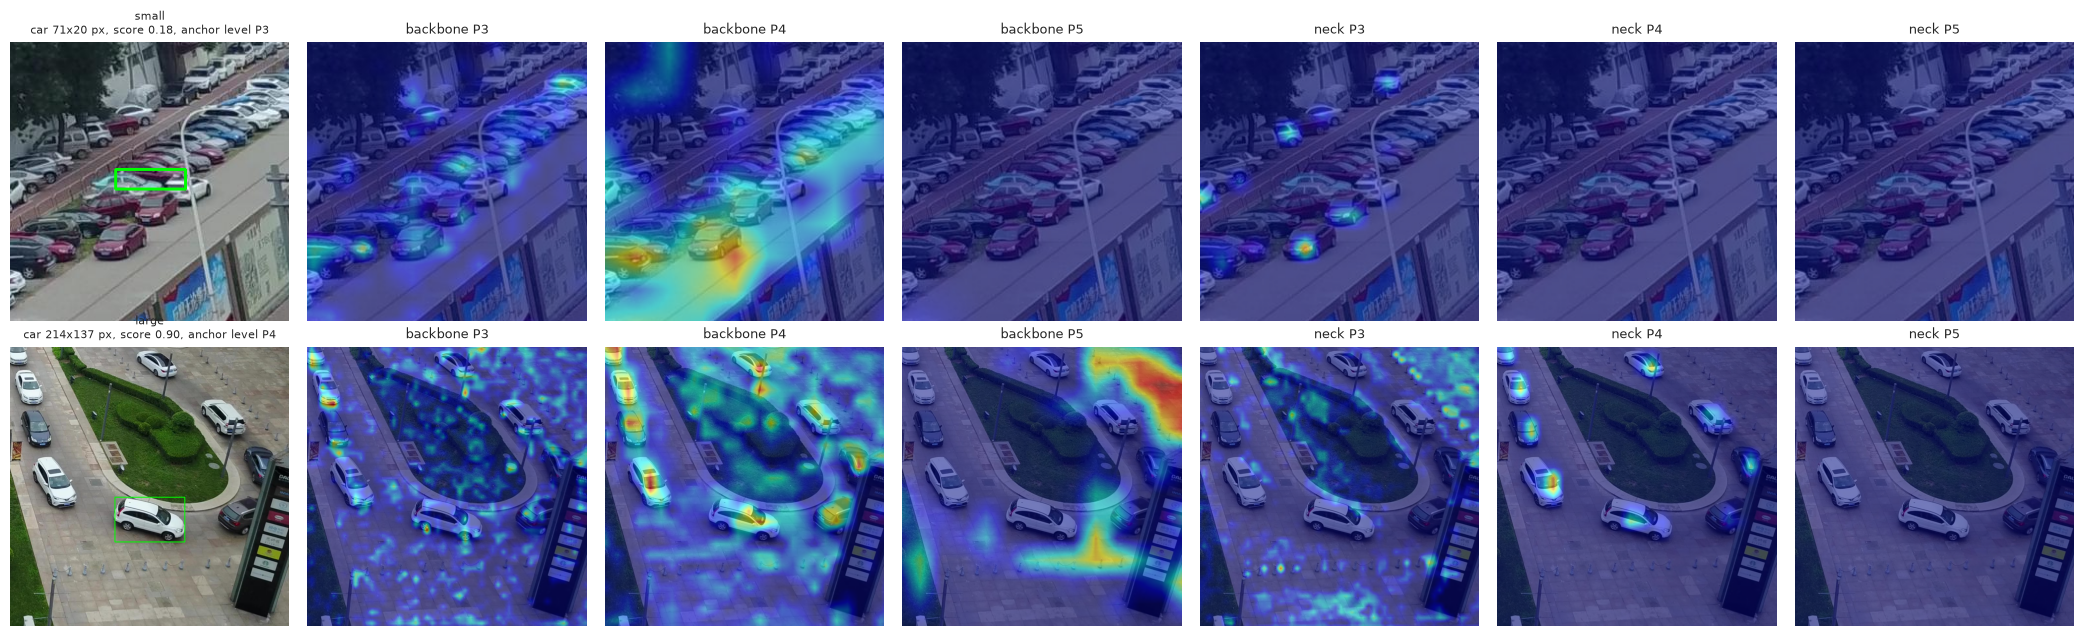

In [2]:
net = load_net(YOLO_W, "yolo")
LAYERS = list(YOLO_LAYERS)
def cam_row(axes, key, g, title):
    row = vrow.loc[key]; img = cv2.imread(row.path); H, W = img.shape[:2]
    b = (g.x, g.y, g.w, g.h); crop = crop_around(b, W, H)
    maps, info = gradcam_yolo(net, img, (g.x, g.y, g.x + g.w, g.y + g.h), int(g.cls))
    im = img[:, :, ::-1].copy(); cv2.rectangle(im, (int(g.x), int(g.y)), (int(g.x + g.w), int(g.y + g.h)), (0, 255, 0), 2)
    axes[0].imshow(im[crop[1]:crop[3], crop[0]:crop[2]]); axes[0].set_title(f"{title}\n{CLASSES[int(g.cls)]} {int(g.w)}x{int(g.h)} px, score {info['score']:.2f}, anchor level P{info['level'] + 3}", fontsize=8)
    for ax, n in zip(axes[1:], LAYERS):
        ax.imshow(overlay(img, maps[n], crop=crop)); ax.set_title(n, fontsize=9)
    for ax in axes: ax.axis("off")

# one dense frame, a small and a large object of the same class
k = val.key.iloc[200]; g = gt[(gt.key == k) & (gt.cls == 2)].sort_values("size")
fig, axes = plt.subplots(2, 7, figsize=(21, 6.4))
cam_row(axes[0], k, g.iloc[len(g) // 8], "small"); cam_row(axes[1], k, g.iloc[-1], "large")
fig.tight_layout(); fig.savefig(IMG / "viz_gradcam_small_large.png", dpi=110); plt.show()

### Found versus missed

Same model, same frame type: a small object that `yolo_base` detects (score ≥ 0.3, IoU ≥ 0.5) next to one it misses.

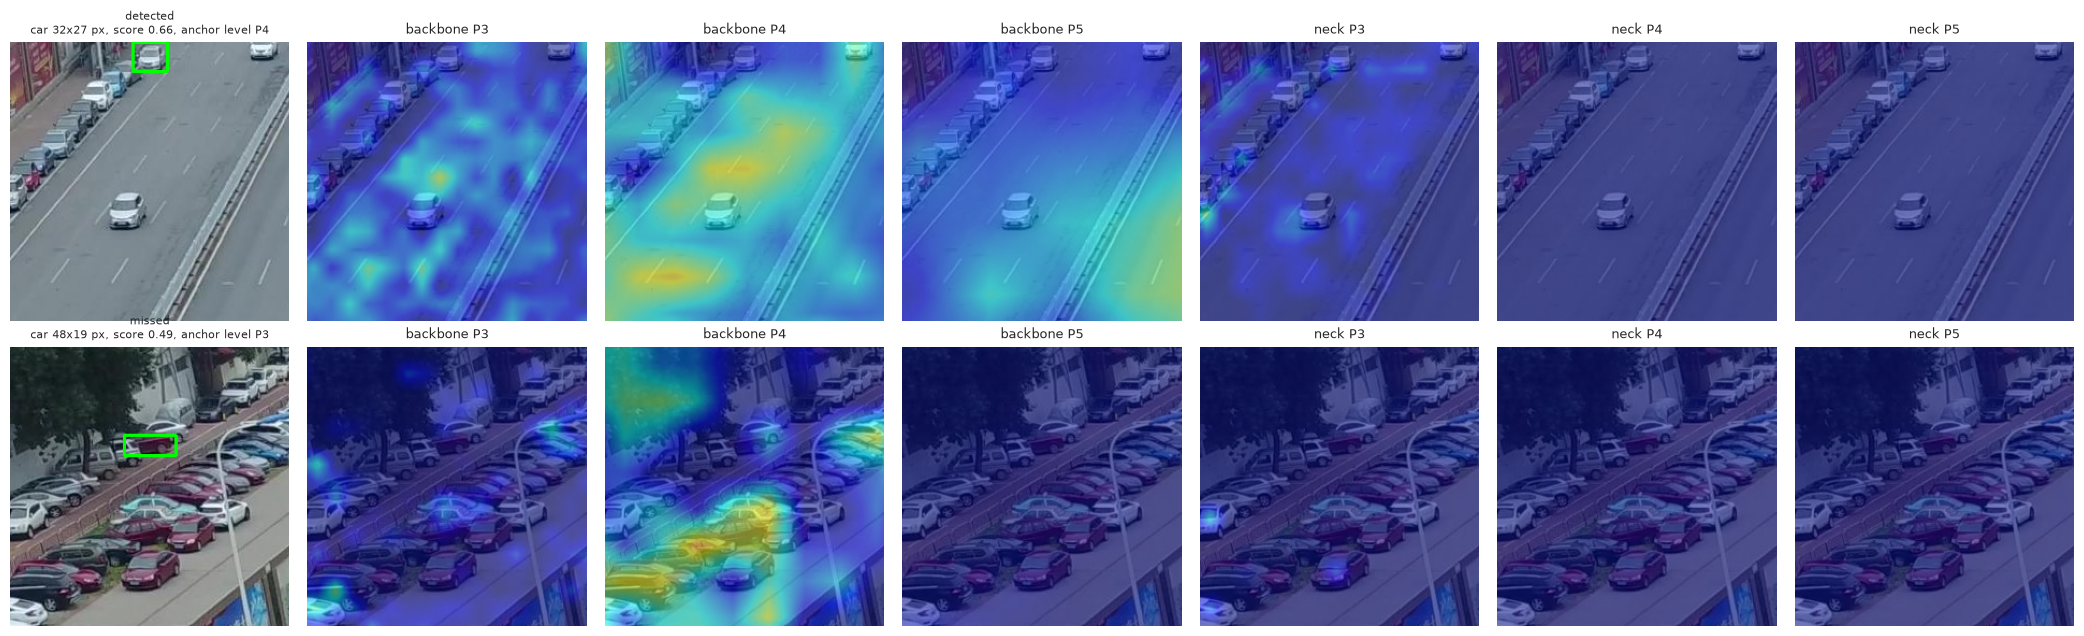

In [3]:
pv = pd.read_parquet("../runs/yolo_base/val_preds.parquet"); pv = pv[pv.score >= 0.3]
def status(k, g):
    p = pv[(pv.key == k) & (pv.cls == g.cls)]
    if not len(p): return False
    iou = iou_matrix(np.array([[g.x, g.y, g.x + g.w, g.y + g.h]]), np.stack([p.x, p.y, p.x + p.w, p.y + p.h], 1))
    return bool(iou.max() >= 0.5)
cand = gt[(gt["bin"] == BINS[0]) & (gt.cls == 2) & (gt.key.isin(val.key.iloc[100:400:3]))].sample(60, random_state=1)
cand["found"] = [status(r.key, r) for r in cand.itertuples()]
found, missed = cand[cand.found].iloc[0], cand[~cand.found].iloc[0]
fig, axes = plt.subplots(2, 7, figsize=(21, 6.4))
cam_row(axes[0], found.key, found, "detected"); cam_row(axes[1], missed.key, missed, "missed")
fig.tight_layout(); fig.savefig(IMG / "viz_gradcam_found_missed.png", dpi=110); plt.show()

### Which level explains which object size?

For 90 ground-truth objects (30 per size bin) from random frames we record (a) the stride level of the prediction chosen as target and (b) how concentrated each Grad-CAM map is on the object: the share of the map's mass that falls in the box dilated by 16 px, divided by the share of the image that this window covers (1 = no better than uniform, larger = more focused).

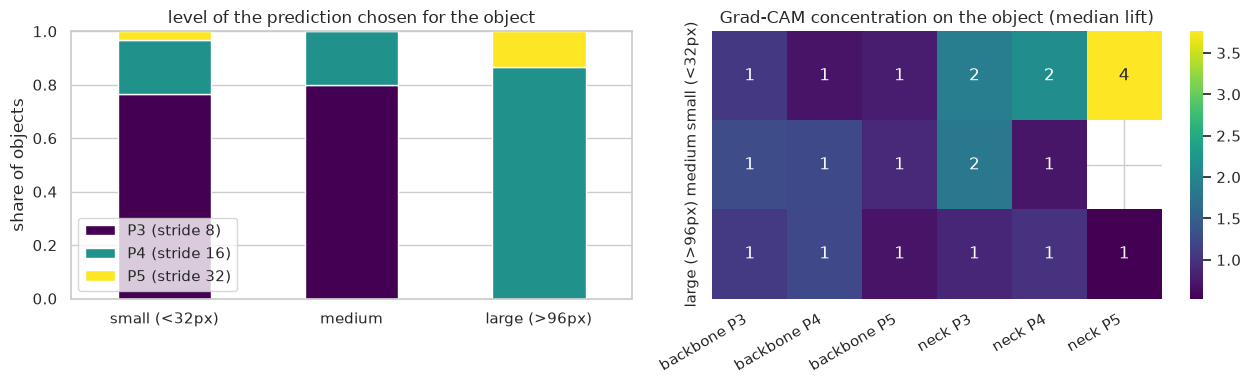

               P3 (stride 8)  P4 (stride 16)  P5 (stride 32)
bin                                                         
small (<32px)           0.77            0.20            0.03
medium                  0.80            0.20            0.00
large (>96px)           0.00            0.87            0.13


layer,backbone P3,backbone P4,backbone P5,neck P3,neck P4,neck P5
bin,,,,,,
small (<32px),1.1,0.7,0.8,1.9,2.1,3.8
medium,1.3,1.2,0.9,1.8,0.7,NaN
large (>96px),1.1,1.2,0.7,0.9,1.0,0.5


In [4]:
rows = []
sample = pd.concat([gt[gt["bin"] == b].sample(30, random_state=0) for b in BINS])
for r in sample.itertuples():
    row = vrow.loc[r.key]; img = cv2.imread(row.path); H, W = img.shape[:2]
    maps, info = gradcam_yolo(net, img, (r.x, r.y, r.x + r.w, r.y + r.h), int(r.cls))
    x0, y0, x1, y1 = int(max(0, r.x - 16)), int(max(0, r.y - 16)), int(min(W, r.x + r.w + 16)), int(min(H, r.y + r.h + 16))
    frac = (x1 - x0) * (y1 - y0) / (W * H)
    for n, m in maps.items():
        tot = m.sum()
        rows.append({"bin": r.bin, "layer": n, "level": info["level"], "lift": (m[y0:y1, x0:x1].sum() / tot) / frac if tot > 0 else np.nan})
cam = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
lvl = cam[cam.layer == LAYERS[0]].groupby("bin", observed=True)["level"].value_counts(normalize=True).unstack().reindex(BINS).fillna(0)
lvl.columns = [f"P{c + 3} (stride {8 * 2 ** c})" for c in lvl.columns]; lvl.plot.bar(stacked=True, ax=ax[0], rot=0, colormap="viridis")
ax[0].set_title("level of the prediction chosen for the object"); ax[0].set_ylabel("share of objects"); ax[0].set_xlabel("")
piv = cam.pivot_table(index="bin", columns="layer", values="lift", aggfunc="median", observed=True).reindex(BINS)[LAYERS]
sns.heatmap(piv, annot=True, fmt=".0f", cmap="viridis", ax=ax[1]); ax[1].set_title("Grad-CAM concentration on the object (median lift)"); ax[1].set_xlabel(""); ax[1].set_ylabel("")
plt.setp(ax[1].get_xticklabels(), rotation=30, ha="right"); fig.tight_layout(); fig.savefig(IMG / "viz_gradcam_levels.png", dpi=130); plt.show()
print(lvl.round(2)); piv.round(1)

In [5]:
del net; gc.collect(); torch.cuda.empty_cache()

## 2 · RT-DETR: deformable attention in the decoder

Every decoder layer lets each query sample 8 heads × 12 points (4 per feature level, levels = strides 8/16/32 at 1536 px input). We keep the sampling locations and attention weights of all six decoder layers, for 60 random validation frames, and look at the queries that end up as confident detections (score ≥ 0.5). A forward pass of our own reproduces the saved predictions of the model (checked on a frame: 185 vs 186 detections above 0.3, identical best box).

In [6]:
rt = load_net(RT_W, "rtdetr")
keys = list(pd.Series(val.key).sample(60, random_state=0))
att, emb_rows, emb_x = [], [], []
LEVELS = ["P3 (stride 8)", "P4 (stride 16)", "P5 (stride 32)"]
store = {}
for fi, k in enumerate(keys):
    img = cv2.imread(vrow.loc[k].path); o = rtdetr_run(rt, img)
    g = gt[gt.key == k]; gxy = np.stack([g.x, g.y, g.x + g.w, g.y + g.h], 1) if len(g) else np.zeros((0, 4))
    iou = iou_matrix(o["xyxy"], gxy) if len(g) else np.zeros((300, 0))
    best = iou.argmax(1) if len(g) else np.zeros(300, int); biou = iou.max(1) if len(g) else np.zeros(300)
    wh = np.sqrt(np.clip(o["xyxy"][:, 2] - o["xyxy"][:, 0], 1, None) * np.clip(o["xyxy"][:, 3] - o["xyxy"][:, 1], 1, None))
    sel = np.where(o["score"] >= 0.5)[0]
    for q in sel:
        for li, L in enumerate(o["layers"]):
            share = np.array([L["w"][q][:, L["level"] == j].sum(1).mean() for j in range(3)])
            att.append({"key": k, "q": q, "layer": li + 1, "size": wh[q], "spread": attention_spread(L, q), **{f"lvl{j}": share[j] for j in range(3)}})
    for q in np.where(o["score"] >= 0.3)[0]:
        if biou[q] >= 0.5: out = "correct class" if int(g.cls.iloc[best[q]]) == int(o["cls"][q]) else "wrong class"
        else: out = "no object (false alarm)"
        emb_rows.append({"key": k, "q": q, "cls": CLASSES[int(o["cls"][q])], "size": wh[q], "outcome": out, "score": o["score"][q]}); emb_x.append(o["emb"][q])
    if fi == 0: store = {"o": o, "k": k}
att = pd.DataFrame(att); att["bin"] = pd.cut(att["size"] ** 2, [0, 32 ** 2, 96 ** 2, 1e9], labels=BINS)
emb = pd.DataFrame(emb_rows); emb_x = np.stack(emb_x)
print(len(keys), "frames,", att.groupby("key").q.nunique().sum(), "confident queries,", len(emb), "embeddings")

60 frames, 4098 confident queries, 5937 embeddings


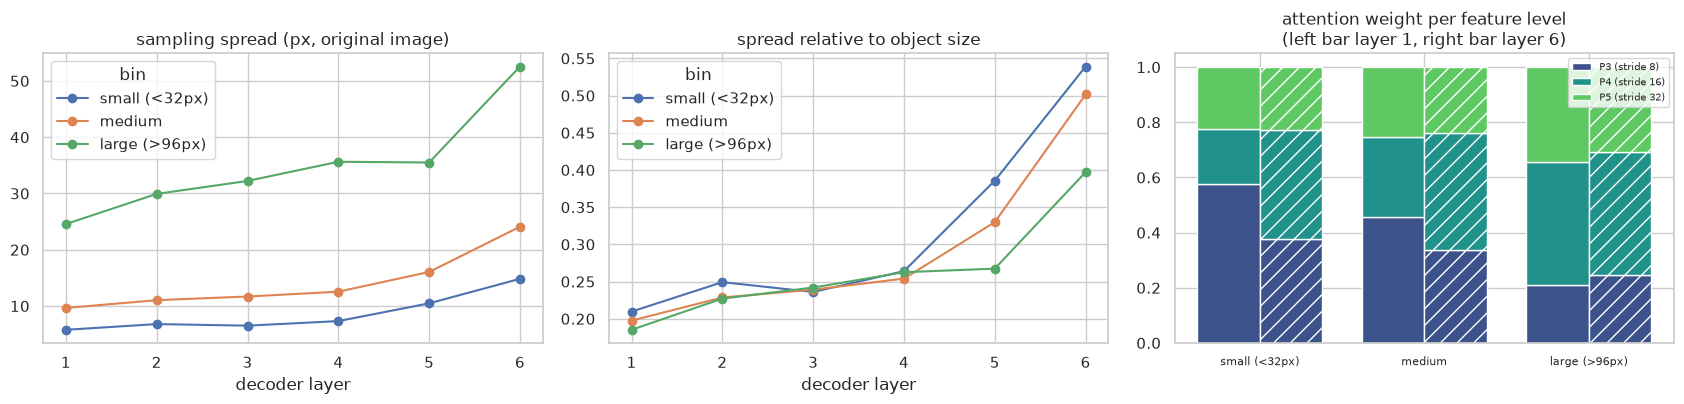

bin    small (<32px)  medium  large (>96px)
layer                                      
1                5.8     9.7           24.6
2                6.8    11.0           29.9
3                6.5    11.7           32.2
4                7.3    12.5           35.6
5               10.5    16.1           35.5
6               14.8    24.1           52.6
bin    small (<32px)  medium  large (>96px)
layer                                      
1               0.21    0.20           0.19
2               0.25    0.23           0.23
3               0.24    0.24           0.24
4               0.26    0.25           0.26
5               0.39    0.33           0.27
6               0.54    0.50           0.40
bin    small (<32px)  medium  large (>96px)
layer                                      
1               0.58    0.46           0.21
2               0.62    0.50           0.28
3               0.65    0.55           0.32
4               0.65    0.56           0.38
5               0.59    0.53    

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sp = att.groupby(["layer", "bin"], observed=True).spread.median().unstack()[BINS]; sp.plot(marker="o", ax=ax[0]); ax[0].set_title("sampling spread (px, original image)"); ax[0].set_xlabel("decoder layer")
att["rel"] = att.spread / att["size"]
rl = att.groupby(["layer", "bin"], observed=True).rel.median().unstack()[BINS]; rl.plot(marker="o", ax=ax[1]); ax[1].set_title("spread relative to object size"); ax[1].set_xlabel("decoder layer")
share = att.groupby(["layer", "bin"], observed=True)[["lvl0", "lvl1", "lvl2"]].mean().reset_index()
last = share[share.layer == 6].set_index("bin")[["lvl0", "lvl1", "lvl2"]].reindex(BINS); first = share[share.layer == 1].set_index("bin")[["lvl0", "lvl1", "lvl2"]].reindex(BINS)
w = 0.38; xs = np.arange(3)
for i, (d, name, hatch) in enumerate(((first, "layer 1", ""), (last, "layer 6", "//"))):
    bottom = np.zeros(3)
    for j, c in enumerate(["lvl0", "lvl1", "lvl2"]):
        ax[2].bar(xs + (i - 0.5) * w, d[c].values, w, bottom=bottom, color=sns.color_palette("viridis", 3)[j], hatch=hatch, edgecolor="white", label=LEVELS[j] if i == 0 else None); bottom += d[c].values
ax[2].set_xticks(xs); ax[2].set_xticklabels(BINS, fontsize=8); ax[2].set_title("attention weight per feature level\n(left bar layer 1, right bar layer 6)"); ax[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig(IMG / "viz_rtdetr_attention.png", dpi=130); plt.show()
print(sp.round(1)); print(rl.round(2)); print(share.round(2).pivot(index="layer", columns="bin", values="lvl0").round(2))

### Where the points land (one frame)

Sampling points of one small and one large confident query: marker size ∝ attention weight, colour = decoder layer 1, 3, 6; box = the query's prediction.

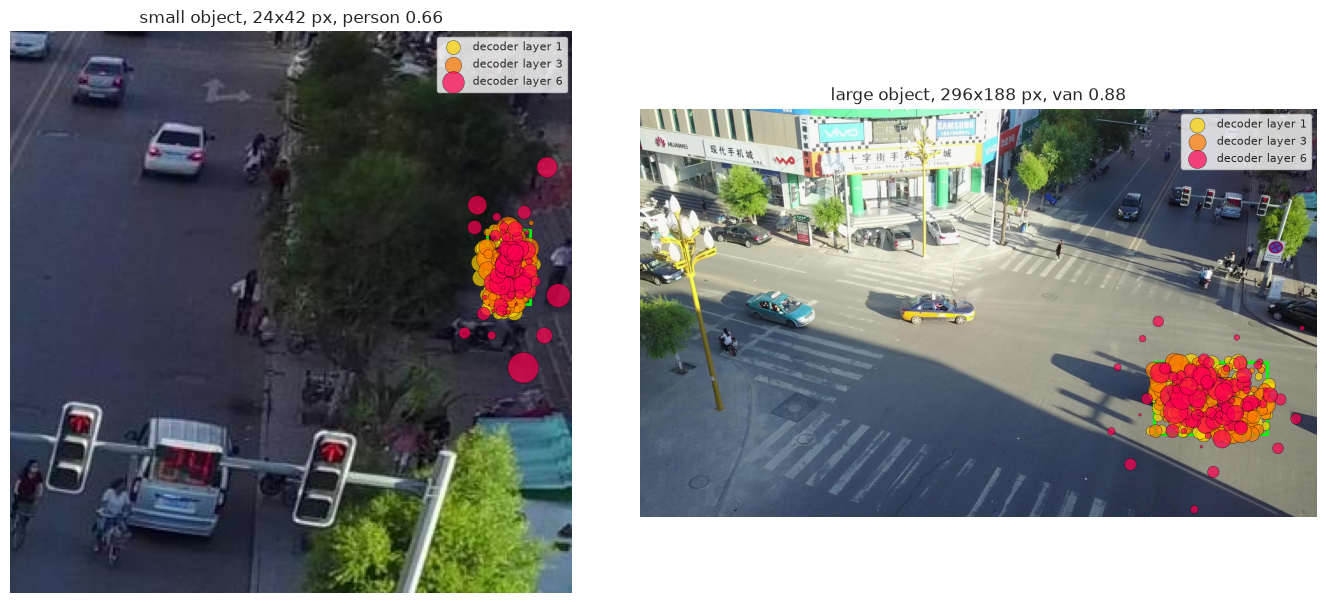

In [8]:
o, k = store["o"], store["k"]; img = cv2.imread(vrow.loc[k].path); H, W = img.shape[:2]
conf = np.where(o["score"] >= 0.5)[0]; wh = np.sqrt((o["xyxy"][:, 2] - o["xyxy"][:, 0]) * (o["xyxy"][:, 3] - o["xyxy"][:, 1]))
qs = {"small": conf[np.argsort(wh[conf])[len(conf) // 10]], "large": conf[np.argsort(wh[conf])[-1]]}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, (name, q) in zip(axes, qs.items()):
    b = o["xyxy"][q]; c = crop_around((b[0], b[1], b[2] - b[0], b[3] - b[1]), W, H, scale=6, min_side=320)
    ax.imshow(img[c[1]:c[3], c[0]:c[2], ::-1]); ax.add_patch(plt.Rectangle((b[0] - c[0], b[1] - c[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=2))
    for li, col in ((0, "#ffd400"), (2, "#ff7a00"), (5, "#ff0050")):
        L = o["layers"][li]; xy = L["xy"][q].reshape(-1, 2); wt = L["w"][q].reshape(-1)
        ax.scatter(xy[:, 0] - c[0], xy[:, 1] - c[1], s=wt * 900, c=col, alpha=0.7, edgecolors="black", linewidths=0.3, label=f"decoder layer {li + 1}")
    ax.set_xlim(0, c[2] - c[0]); ax.set_ylim(c[3] - c[1], 0); ax.axis("off"); ax.set_title(f"{name} object, {int(b[2] - b[0])}x{int(b[3] - b[1])} px, {CLASSES[int(o['cls'][q])]} {o['score'][q]:.2f}"); ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); fig.savefig(IMG / "viz_rtdetr_attention_points.png", dpi=120); plt.show()

## 3 · RT-DETR query embeddings (t-SNE)

The 256-d embedding of the last decoder layer for every query with score ≥ 0.3 in the same 60 frames, projected to 2-D. Colours: predicted class, object size, and whether the detection was right (IoU ≥ 0.5 with a ground-truth box of the same class), a class confusion (IoU ≥ 0.5, other class) or a false alarm.

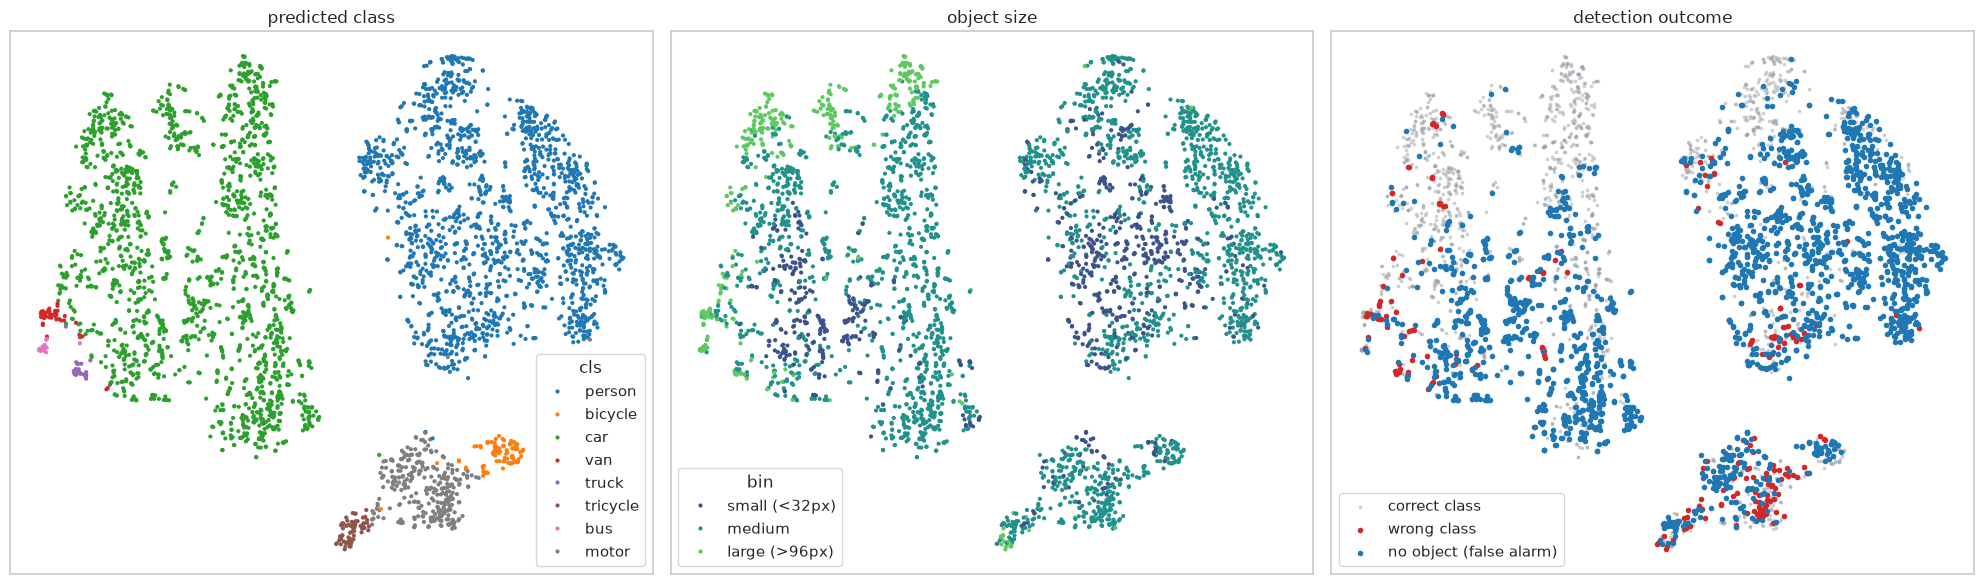

outcome
no object (false alarm)    2050
correct class              1729
wrong class                 221
Name: count, dtype: int64
outcome
correct class              0.745
no object (false alarm)    0.526
wrong class                0.617
Name: score, dtype: float32


In [9]:
from sklearn.manifold import TSNE
n = min(len(emb), 4000); sel = rng.choice(len(emb), n, replace=False)
Z = TSNE(n_components=2, perplexity=40, init="pca", random_state=0).fit_transform(emb_x[sel])
e = emb.iloc[sel].reset_index(drop=True); e["x"], e["y"] = Z[:, 0], Z[:, 1]
e["bin"] = pd.cut(e["size"] ** 2, [0, 32 ** 2, 96 ** 2, 1e9], labels=BINS)
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
sns.scatterplot(data=e, x="x", y="y", hue="cls", hue_order=CLASSES, s=9, linewidth=0, ax=ax[0], palette="tab10"); ax[0].set_title("predicted class")
sns.scatterplot(data=e, x="x", y="y", hue="bin", s=9, linewidth=0, ax=ax[1], palette="viridis"); ax[1].set_title("object size")
order = ["correct class", "wrong class", "no object (false alarm)"]; pal = dict(zip(order, ["#9aa0a6", "#d62728", "#1f77b4"]))
sns.scatterplot(data=e[e.outcome == order[0]], x="x", y="y", color=pal[order[0]], s=7, linewidth=0, alpha=0.5, ax=ax[2], label=order[0])
for o_ in order[1:]: sns.scatterplot(data=e[e.outcome == o_], x="x", y="y", color=pal[o_], s=16, linewidth=0, ax=ax[2], label=o_)
ax[2].set_title("detection outcome")
for a in ax: a.set_xticks([]); a.set_yticks([]); a.set_xlabel(""); a.set_ylabel("")
fig.tight_layout(); fig.savefig(IMG / "viz_rtdetr_tsne.png", dpi=120); plt.show()
print(e.outcome.value_counts()); print(e.groupby("outcome").score.mean().round(3))

### How separable are the classes in embedding space?

k-nearest-neighbour check in the original 256-d space (k = 10, leave-one-out): how often does the majority class of a detection's neighbours equal its predicted class, per class.

In [10]:
from sklearn.neighbors import NearestNeighbors
X = emb_x; y = emb.cls.values
nn = NearestNeighbors(n_neighbors=11, metric="cosine").fit(X); idx = nn.kneighbors(X, return_distance=False)[:, 1:]
maj = np.array([pd.Series(y[i]).mode()[0] for i in idx])
purity = pd.DataFrame({"class": y, "agree": maj == y, "outcome": emb.outcome.values})
print("overall:", purity.agree.mean().round(3)); print(purity.groupby("class").agree.agg(["mean", "size"]).round(3).T)
print(purity.groupby("outcome").agree.mean().round(3))

overall: 0.995
class  bicycle     bus     car    motor    person  tricycle   truck     van
mean     0.952   0.923     1.0    0.985     0.999     0.992   0.921   0.868
size   147.000  26.000  2755.0  412.000  2373.000   118.000  38.000  68.000
outcome
correct class              0.999
no object (false alarm)    0.993
wrong class                0.975
Name: agree, dtype: float64
